In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from xgboost import XGBClassifier,plot_importance
from sklearn.metrics import confusion_matrix,accuracy_score,classification_report,ConfusionMatrixDisplay
from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split

In [2]:
'''
Pipeline helps to automate sequence of preprocessing and model training steps,
ensuring the same transformations are consistently applied to both training and testing data
'''
#read the dataset
df=pd.read_csv("titanic.csv")


In [3]:
#display dataset information
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [4]:
#check missing values
df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [5]:
df.shape

(891, 12)

In [6]:
#handle missing values
df=df.dropna(subset=['Embarked'])

In [7]:
df['Cabin'].unique()

array([nan, 'C85', 'C123', 'E46', 'G6', 'C103', 'D56', 'A6',
       'C23 C25 C27', 'B78', 'D33', 'B30', 'C52', 'C83', 'F33', 'F G73',
       'E31', 'A5', 'D10 D12', 'D26', 'C110', 'B58 B60', 'E101', 'F E69',
       'D47', 'B86', 'F2', 'C2', 'E33', 'B19', 'A7', 'C49', 'F4', 'A32',
       'B4', 'B80', 'A31', 'D36', 'D15', 'C93', 'C78', 'D35', 'C87',
       'B77', 'E67', 'B94', 'C125', 'C99', 'C118', 'D7', 'A19', 'B49',
       'D', 'C22 C26', 'C106', 'C65', 'E36', 'C54', 'B57 B59 B63 B66',
       'C7', 'E34', 'C32', 'B18', 'C124', 'C91', 'E40', 'T', 'C128',
       'D37', 'B35', 'E50', 'C82', 'B96 B98', 'E10', 'E44', 'A34', 'C104',
       'C111', 'C92', 'E38', 'D21', 'E12', 'E63', 'A14', 'B37', 'C30',
       'D20', 'B79', 'E25', 'D46', 'B73', 'C95', 'B38', 'B39', 'B22',
       'C86', 'C70', 'A16', 'C101', 'C68', 'A10', 'E68', 'B41', 'A20',
       'D19', 'D50', 'D9', 'A23', 'B50', 'A26', 'D48', 'E58', 'C126',
       'B71', 'B51 B53 B55', 'D49', 'B5', 'B20', 'F G63', 'C62 C64',
       'E24',

In [8]:
df=df.drop(columns=['Cabin'])

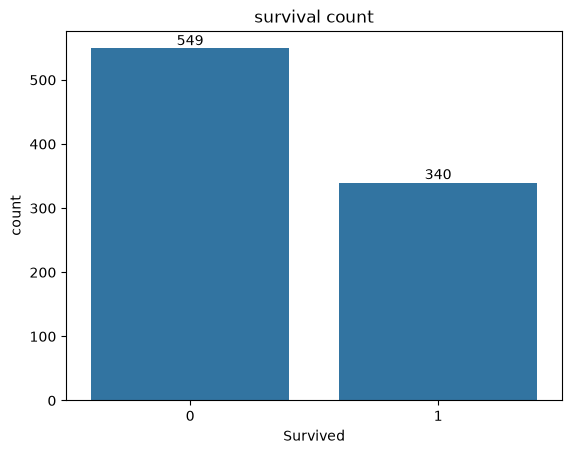

In [9]:
#target variable 
ax=sns.countplot(x='Survived',data=df)
for c in ax.containers:
    ax.bar_label(c,fmt='%d')
plt.title("survival count")
plt.show()

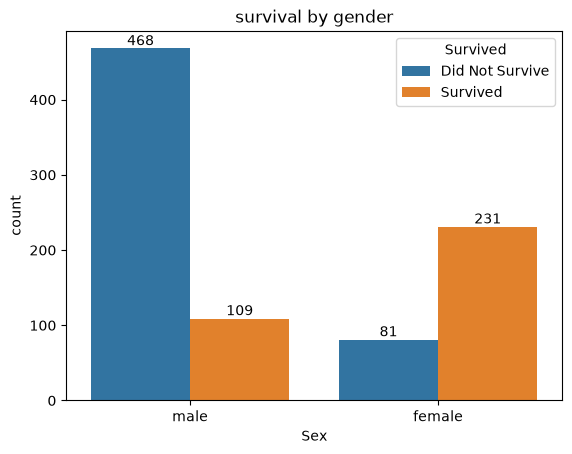

In [10]:
df_plot = df.copy()

df_plot["Survived"] = df_plot["Survived"].map({
    0: "Did Not Survive",
    1: "Survived"
})
ax=sns.countplot(x='Sex', hue='Survived', data=df_plot)
for c in ax.containers:
    ax.bar_label(c,fmt='%d')
plt.title("survival by gender")
plt.show()

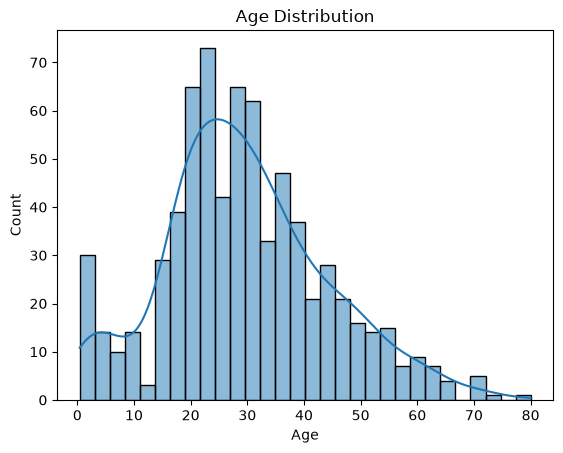

In [11]:
'''kde=True
KDE stands for Kernel Density Estimation.
It draws a smooth density curve over the histogram.'''
sns.histplot(df['Age'],bins=30,kde=True)
plt.title("Age Distribution")
plt.show()

In [12]:
df.corr(numeric_only=True)

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
PassengerId,1.000000,-0.005028,-0.035330,0.033681,-0.057686,-0.001657,0.012703
Survived,-0.005028,1.000000,-0.335549,-0.082446,-0.034040,0.083151,0.255290
Pclass,-0.035330,-0.335549,1.000000,-0.365902,0.081656,0.016824,-0.548193
Age,0.033681,-0.082446,-0.365902,1.000000,-0.307351,-0.187896,0.093143
SibSp,-0.057686,-0.034040,0.081656,-0.307351,1.000000,0.414542,0.160887
Parch,-0.001657,0.083151,0.016824,-0.187896,0.414542,1.000000,0.217532
Fare,0.012703,0.255290,-0.548193,0.093143,0.160887,0.217532,1.000000


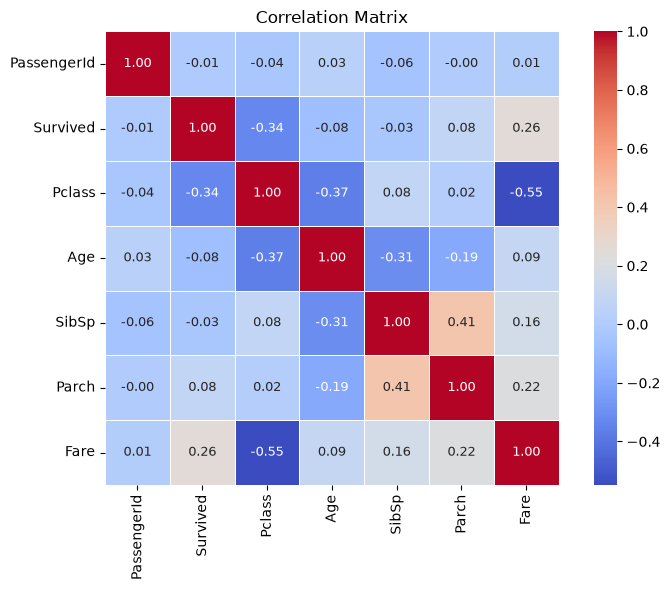

In [13]:
plt.figure(figsize=(8,6))

corr = df.corr(numeric_only=True)

sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    linewidths=0.5,
    square=True,
    annot_kws={"size":9}
)

plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()

In [14]:
df['Survived'].value_counts()

Survived
0    549
1    340
Name: count, dtype: int64

In [15]:
#select features and target
X=df.drop(columns=['PassengerId','Name','Ticket','Survived'])

In [28]:
print(X.columns.tolist())

['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked']


In [16]:
y=df['Survived']

In [17]:
y.value_counts()

Survived
0    549
1    340
Name: count, dtype: int64

In [18]:
# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [19]:
# ColumnTransformer: Applies different preprocessing methods to selected columns.
preprocessor=ColumnTransformer(
    transformers=[
        ('ordinal',OrdinalEncoder(),['Sex']),
        ('onehot',OneHotEncoder(handle_unknown='ignore'),['Embarked'])
    ],
    remainder='passthrough'
)

In [20]:
'''
n_estimators=100 – Number of trees (boosting rounds) to build.
learning_rate=0.1 – Controls how much each tree contributes to the final model.
max_depth=3 – Maximum depth of each decision tree.
subsample=0.8 – Fraction of training samples used to build each tree.
colsample_bytree=0.8 – Fraction of features used to build each tree.
min_child_weight=1 – Minimum sum of instance weights required in a child node before further splitting.
gamma=0 – Minimum loss reduction required to create a new split.
reg_alpha=0 – L1 regularization parameter to reduce overfitting.
reg_lambda=1 – L2 regularization parameter to improve model generalization.
random_state=42 – Sets a fixed random seed to ensure reproducible results'''

model=XGBClassifier(n_estimators=100, learning_rate=0.1,max_depth=3,subsample=0.8,colsample_bytree=0.8,min_child_weight=1,
                    gamma=0,reg_alpha=0,reg_lambda=1,random_state=42)

In [21]:
pipeline = Pipeline([
    ('preprocessing', preprocessor),
    ('classifier', model)
])

In [22]:
pipeline.fit(X_train, y_train)

C:\Users\HP\AppData\Roaming\Python\Python311\site-packages\xgboost\training.py:200: UserWarning: [01:50:47] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:782: 
Parameters: { "min_child_Weight", "reg_Alpha" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


Pipeline(steps=[('preprocessing',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('ordinal', OrdinalEncoder(),
                                                  ['Sex']),
                                                 ('onehot',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['Embarked'])])),
                ('classifier',
                 XGBClassifier(base_score=None, booster=None, callbacks=None,
                               colsample_bylevel=None, colsample_bynode=None,
                               colsample_bytree=0.8, device=None,
                               early_st...
                               feature_types=None, feature_weights=None,
                               gamma=0, grow_policy=None, importance_type=None,
                               interaction_constraints=None, learning_rate=0.1,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=3, max_leaves=None, min_child_Weight=1,
                               min_child_weight=None, missing=nan,
                               monotone_constraints=None, multi_strategy=None,
                               n_estimators=100, n_jobs=None, ...))])

In [23]:
y_pred = pipeline.predict(X_test)

In [24]:
accuracy = accuracy_score(y_test, y_pred)
print("Accuracy Score:", accuracy)

Accuracy Score: 0.8146067415730337


In [25]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.83      0.87      0.85       110
           1       0.78      0.72      0.75        68

    accuracy                           0.81       178
   macro avg       0.81      0.80      0.80       178
weighted avg       0.81      0.81      0.81       178



In [26]:
cm = confusion_matrix(y_test, y_pred)
print(cm)

[[96 14]
 [19 49]]


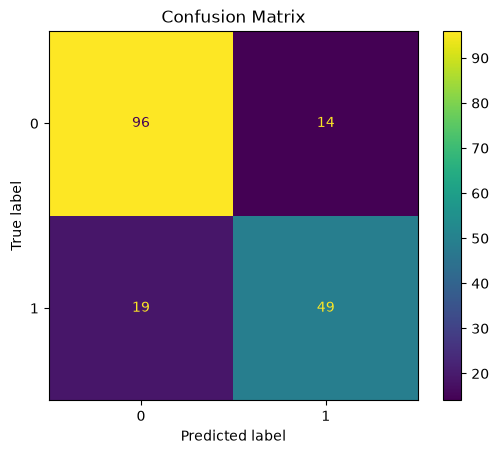

In [27]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(y_test, y_pred)
plt.title("Confusion Matrix")
plt.show()